In [1]:
import csv

import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

RANDOM_SEED = 42

I0000 00:00:1794718923.413550   94589 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794718923.456161   94589 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794718924.583883   94589 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


# Specify each path

In [2]:
dataset = 'model/keypoint_classifier/keypoint.csv'
label_path = 'model/keypoint_classifier/keypoint_classifier_label.csv'
model_save_path = 'model/keypoint_classifier/keypoint_classifier.keras'
tflite_save_path = 'model/keypoint_classifier/keypoint_classifier.tflite'

# Set number of hands and classes

One sample = **both hands in a single CSV row**: `2 hands x 21 landmarks x 2 coordinates = 84` features.
Class `inactive` is used whenever fewer than two hands are visible.

In [3]:
NUM_HANDS = 2
NUM_LANDMARKS = 21
NUM_FEATURES = NUM_HANDS * NUM_LANDMARKS * 2  # 84

NUM_CLASSES = 5  # Push, Heal, Choke, Lightning, inactive

# Dataset reading

In [4]:
with open(label_path, encoding='utf-8-sig') as f:
    label_names = [row[0] for row in csv.reader(f) if row]

assert len(label_names) == NUM_CLASSES, (
    '{} contains {} labels, expected {}: {}'.format(
        label_path, len(label_names), NUM_CLASSES, label_names))
label_names

['Push', 'Heal', 'Choke', 'Lightning', 'inactive']

In [5]:
# Every row must be: class id + NUM_HANDS * NUM_LANDMARKS * 2 features.
# Old single-hand rows (43 columns) would silently train the wrong model,
# so they are rejected here with a clear message.
expected_columns = NUM_FEATURES + 1
bad_rows = []
with open(dataset, encoding='utf-8-sig', newline='') as f:
    for line_no, row in enumerate(csv.reader(f), start=1):
        if row and len(row) != expected_columns:
            bad_rows.append((line_no, len(row)))

if bad_rows:
    preview = ', '.join('line {} ({} columns)'.format(n, c)
                        for n, c in bad_rows[:5])
    raise ValueError(
        '{}: {} row(s) do not have {} columns (1 class + {} features). '
        'First offenders: {}. Old single-hand rows (43 columns) must be '
        'removed or re-recorded with app.py.'.format(
            dataset, len(bad_rows), expected_columns, NUM_FEATURES, preview))

print('{}: all rows have {} columns'.format(dataset, expected_columns))

model/keypoint_classifier/keypoint.csv: all rows have 85 columns


In [6]:
X_dataset = np.loadtxt(dataset, delimiter=',', dtype='float32',
                       usecols=list(range(1, NUM_FEATURES + 1)))

In [7]:
y_dataset = np.loadtxt(dataset, delimiter=',', dtype='int32', usecols=(0,))

In [8]:
# Shape/label sanity checks + per-class sample counts
if X_dataset.ndim == 1:
    X_dataset = X_dataset.reshape(1, -1)
if y_dataset.ndim == 0:
    y_dataset = y_dataset.reshape(1)

assert X_dataset.shape[1] == NUM_FEATURES, X_dataset.shape
assert y_dataset.min() >= 0 and y_dataset.max() < NUM_CLASSES, (
    'class ids outside 0..{}: {}'.format(
        NUM_CLASSES - 1, np.unique(y_dataset).tolist()))

class_counts = np.bincount(y_dataset, minlength=NUM_CLASSES)
for class_id in range(NUM_CLASSES):
    print('{} {}: {} samples'.format(
        class_id, label_names[class_id], class_counts[class_id]))

assert class_counts.min() > 0, (
    'no samples for class(es): {}'.format(
        [label_names[i] for i in range(NUM_CLASSES)
         if class_counts[i] == 0]))

0 Push: 400 samples
1 Heal: 241 samples
2 Choke: 241 samples
3 Lightning: 239 samples
4 inactive: 128 samples


In [9]:
# Stratify only when every class has at least 2 samples, otherwise
# train_test_split raises for the missing classes.
stratify = y_dataset if class_counts.min() >= 2 else None

X_train, X_test, y_train, y_test = train_test_split(
    X_dataset, y_dataset, train_size=0.75,
    random_state=RANDOM_SEED, stratify=stratify)

# Model building

In [10]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Input((NUM_FEATURES, )),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(20, activation='relu'),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(10, activation='relu'),
    tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')
])

E0000 00:00:1794718926.215618   94589 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



In [11]:
model.summary()  # tf.keras.utils.plot_model(model, show_shapes=True)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dropout (Dropout)               │ (None, 84)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 20)             │         1,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 20)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           210 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │            55 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,965 (7.68 KB)

 Trainable params: 1,965 (7.68 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
cp_callback = tf.keras.callbacks.ModelCheckpoint(
    model_save_path, verbose=1, save_weights_only=False,
    monitor='val_loss', save_best_only=True)
es_callback = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=20, verbose=1,
    restore_best_weights=True)

In [13]:
# Model compilation
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Model training

In [14]:
history = model.fit(
    X_train,
    y_train,
    epochs=1000,
    batch_size=128,
    validation_data=(X_test, y_test),
    callbacks=[cp_callback, es_callback]
)

print('best val accuracy: {:.4f}'.format(max(history.history['val_accuracy'])))

Epoch 1/1000
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.2126 - loss: 1.6457 
Epoch 1: val_loss improved from None to 1.49837, saving model to model/keypoint_classifier/keypoint_classifier.keras

Epoch 1: finished saving model to model/keypoint_classifier/keypoint_classifier.keras
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 79ms/step - accuracy: 0.2126 - loss: 1.6457 - val_accuracy: 0.3994 - val_loss: 1.4984
Epoch 2/1000
1/8 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.2500 - loss: 1.5643
Epoch 2: val_loss improved from 1.49837 to 1.39838, saving model to model/keypoint_classifier/keypoint_classifier.keras

Epoch 2: finished saving model to model/keypoint_classifier/keypoint_classifier.keras
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.2821 - loss: 1.5470 - val_accuracy: 0.4952 - val_loss: 1.3984
Epoch 3/1000
1/8 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.3281 - loss: 1.5020
Epoch 3: val_loss improved from 1.39838 to 1.34159, saving model to model/keypoint_classifier/keypoint_cl

In [15]:
# Model evaluation
val_loss, val_acc = model.evaluate(X_test, y_test, batch_size=128)
print('val_loss: {}, val_acc: {}'.format(val_loss, val_acc))

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9936 - loss: 0.0318 
val_loss: 0.03182300925254822, val_acc: 0.9936102032661438


In [16]:
# Loading the saved model (the best val_loss checkpoint)
model = tf.keras.models.load_model(model_save_path)

In [17]:
# Inference test
predict_result = model.predict(np.array([X_test[0]]), verbose=0)
scores = np.squeeze(predict_result)
print(scores)
print('predicted class: {} ({})'.format(
    np.argmax(scores), label_names[np.argmax(scores)]))

[9.6754974e-01 9.0879130e-06 3.2139603e-02 3.0144502e-04 9.0755866e-12]
predicted class: 0 (Push)


# Confusion matrix

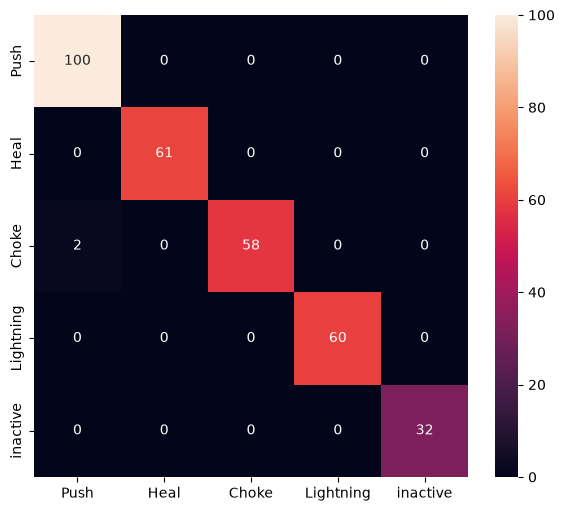

Classification Report
              precision    recall  f1-score   support

        Push       0.98      1.00      0.99       100
        Heal       1.00      1.00      1.00        61
       Choke       1.00      0.97      0.98        60
   Lightning       1.00      1.00      1.00        60
    inactive       1.00      1.00      1.00        32

    accuracy                           0.99       313
   macro avg       1.00      0.99      0.99       313
weighted avg       0.99      0.99      0.99       313



In [18]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

def print_confusion_matrix(y_true, y_pred, report=True):
    # Fixed label range keeps the matrix NUM_CLASSES x NUM_CLASSES even
    # when a class is missing from the test split.
    cmx_data = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))

    df_cmx = pd.DataFrame(cmx_data, index=label_names, columns=label_names)

    fig, ax = plt.subplots(figsize=(7, 6))
    sns.heatmap(df_cmx, annot=True, fmt='g', square=False)
    ax.set_ylim(NUM_CLASSES, 0)
    plt.show()

    if report:
        print('Classification Report')
        print(classification_report(
            y_true, y_pred, labels=range(NUM_CLASSES),
            target_names=label_names, zero_division=0))

Y_pred = model.predict(X_test, verbose=0)
y_pred = np.argmax(Y_pred, axis=1)

print_confusion_matrix(y_test, y_pred)

# Convert to model for Tensorflow-Lite

In [19]:
# Save as a model dedicated to inference
model.save(model_save_path, include_optimizer=False)

In [20]:
# Transform model (quantization)

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_quantized_model = converter.convert()

with open(tflite_save_path, 'wb') as f:
    f.write(tflite_quantized_model)

INFO:tensorflow:Assets written to: /tmp/tmp296tf2l9/assets


INFO:tensorflow:Assets written to: /tmp/tmp296tf2l9/assets


Saved artifact at '/tmp/tmp296tf2l9'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 84), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  132070602028240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132070602030160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132070584589184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132070584592544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132070584590864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132070584582704: TensorSpec(shape=(), dtype=tf.resource, name=None)


W0000 00:00:1794718952.093553   94589 tf_tfl_flatbuffer_helpers.cc:425] Ignored output_format.
W0000 00:00:1794718952.093572   94589 tf_tfl_flatbuffer_helpers.cc:428] Ignored drop_control_dependency.
I0000 00:00:1794718952.093832   94589 reader.cc:83] Reading SavedModel from: /tmp/tmp296tf2l9
I0000 00:00:1794718952.094196   94589 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1794718952.094206   94589 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp296tf2l9
I0000 00:00:1794718952.097326   94589 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1794718952.097672   94589 loader.cc:237] Restoring SavedModel bundle.
I0000 00:00:1794718952.111780   94589 loader.cc:221] Running initialization op on SavedModel bundle at path: /tmp/tmp296tf2l9
I0000 00:00:1794718952.117596   94589 loader.cc:484] SavedModel load for tags { serve }; Status: success: OK. Took 23770 microseconds.
I0000 00:00:1794718952.125882   94589

# Inference test

In [21]:
interpreter = tf.lite.Interpreter(model_path=tflite_save_path)
interpreter.allocate_tensors()

/home/krzysztof/Documents/hand-gesture-recognition-mediapipe-for-game-input/.CVenv/lib/python3.14/site-packages/tensorflow/lite/python/interpreter.py:468: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


In [22]:
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print('input:', input_details[0]['shape'],
      'output:', output_details[0]['shape'])
assert input_details[0]['shape'][-1] == NUM_FEATURES, (
    'TFLite input is {}, expected {} (2 hands x 21 x 2)'.format(
        input_details[0]['shape'], NUM_FEATURES))
assert output_details[0]['shape'][-1] == NUM_CLASSES, (
    'TFLite output is {}, expected {} classes'.format(
        output_details[0]['shape'], NUM_CLASSES))

input: [ 1 84] output: [1 5]


In [23]:
interpreter.set_tensor(input_details[0]['index'],
                       np.array([X_test[0]], dtype=np.float32))

In [24]:
interpreter.invoke()
tflite_results = interpreter.get_tensor(output_details[0]['index'])
print(np.squeeze(tflite_results))
print('predicted class: {} ({})'.format(
    np.argmax(np.squeeze(tflite_results)),
    label_names[np.argmax(np.squeeze(tflite_results))]))

[9.6750569e-01 9.0917647e-06 3.2177977e-02 3.0727155e-04 9.2895006e-12]
predicted class: 0 (Push)
